In [8]:
#Imports
import nflreadpy as nfldat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
from sklearn import linear_model as lm

In [ ]:
#Load stats for all players
player_stats = nfldat.load_player_stats(None, "reg")
pdplayerstats = player_stats.to_pandas()
#Get and print for one player
nabersstats = pdplayerstats[pdplayerstats["player_display_name"] == "Malik Nabers"]
print(nabersstats)

In [ ]:
#Load Weekly Stats
weekly_player_stats_2025 = nfldat.load_player_stats(["2025"], "week")
pdwps2025 = weekly_player_stats_2025.to_pandas()
#Get for a single player
wpsJT = pdwps2025[pdwps2025["player_display_name"] == "Jonathan Taylor"]
wpsJT = wpsJT[wpsJT["season_type"] == "REG"]
print(wpsJT)

In [4]:
#Get only weekly PPR fantasy points and truncate to make it readable
JTpprpoints = wpsJT["fantasy_points_ppr"].tolist()
for i in range (len(JTpprpoints)):
    x = JTpprpoints[i]*100
    x = math.trunc(x)
    JTpprpoints[i] = x/100
print(JTpprpoints)

[12.8, 29.5, 32.79, 14.6, 31.6, 23.7, 34.2, 37.4, 7.7, 49.6, 8.6, 15.1, 11.4, 13.1, 16.89, 17.39, 5.9]


In [5]:
#Get Jonathan Taylor's weekly rushing attempts for 2025 season
#Same Season we got his fantasy points for
nextgenstats = nfldat.load_nextgen_stats(2025, "rushing")
pdngs = nextgenstats.to_pandas()
JTngs = pdngs[pdngs["player_display_name"] == "Jonathan Taylor"]
JTngs = JTngs[JTngs["season_type"] == "REG"]
JTngsRA = JTngs["rush_attempts"].tolist()
JTngsRAbyweek = JTngsRA[1:]
print(JTngsRAbyweek)

[18, 25, 17, 17, 17, 21, 16, 12, 14, 32, 16, 21, 21, 25, 16, 21, 14]


Text(0, 0.5, 'Rush Attempts')

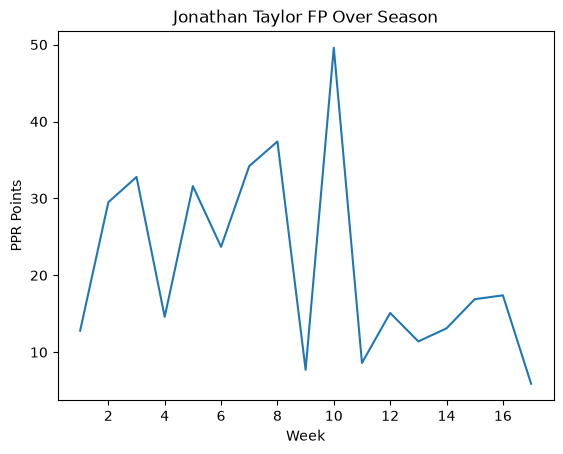

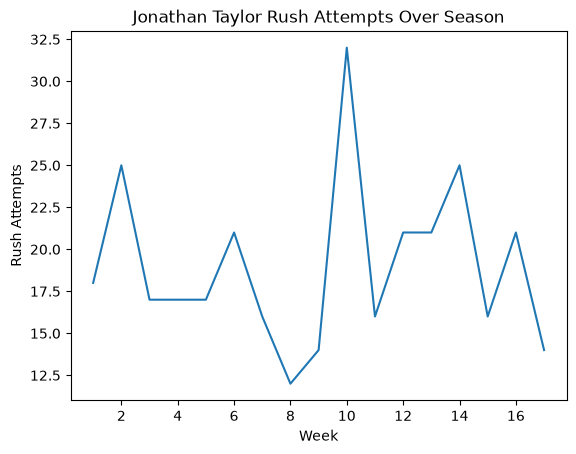

In [6]:
#Plot fantasy points over the season
plt.figure(1)
plt.plot(range(1, len(JTpprpoints)+1), JTpprpoints)
plt.title("Jonathan Taylor FP Over Season")
plt.xlabel("Week")
plt.ylabel("PPR Points")
#Plot rushing attempts over the season
plt.figure(2)
plt.plot(range(1, len(JTngsRAbyweek)+1), JTngsRAbyweek)
plt.title("Jonathan Taylor Rush Attempts Over Season")
plt.xlabel("Week")
plt.ylabel("Rush Attempts")

Text(0.5, 1.0, 'Jonathan Taylor Fantasy Points by Rushing Attempts 2025 Season')

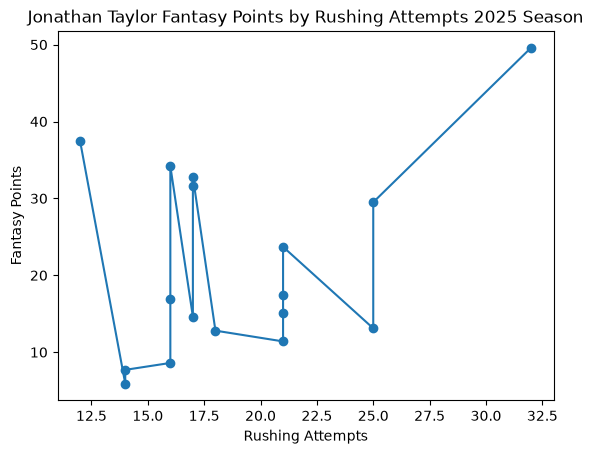

In [7]:
#plot Fantasy Points by Rushing Attempts

#Merge into tuples for sorting
merge = list(zip(JTngsRAbyweek, JTpprpoints))
merge = sorted(merge)
#After sorting, move back to lists
x, y = zip(*merge)
#Plot
plt.plot(x, y, marker = 'o')
plt.xlabel("Rushing Attempts")
plt.ylabel("Fantasy Points")
plt.title("Jonathan Taylor Fantasy Points by Rushing Attempts 2025 Season")

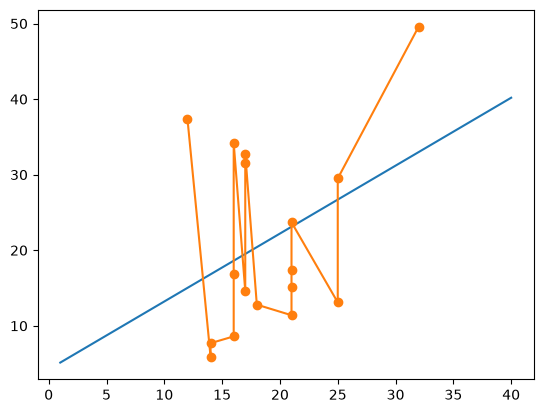

In [43]:
#Simple Linear Regression for the Data
#Using scikit learn
#Get regression model
reg = lm.LinearRegression()
#Take x-values into an array and reshape it to be a list of features
ra = np.array(x)
rashaped = np.reshape(ra, (-1,1))
#take y-values to an array
fp = np.array(y)
#Fit the line
reg.fit(rashaped, fp)
#take coef and intercept
m = float(reg.coef_[0])
b = float(reg.intercept_)
#Make points to plot
xvar = np.linspace(1,40,1000)
yvar = m * xvar + b
#Plot
plt.plot(xvar, yvar)
plt.plot(x,y,marker = "o")
plt.show()

In [ ]:
#This only considers one feature - Rushing Attempts. Lets try the same thing with more features